In [1]:
import pandas as pd

# Читаем только заголовки - Для проверки и предварительного анализа
all_cols = pd.read_csv('../data/flights.csv', nrows=0).columns.tolist()

print(f"Всего колонок в файле: {len(all_cols)}")
print("-" * 30)
for i, col in enumerate(all_cols):
    print(f"{i+1}. {col}")

Всего колонок в файле: 31
------------------------------
1. YEAR
2. MONTH
3. DAY
4. DAY_OF_WEEK
5. AIRLINE
6. FLIGHT_NUMBER
7. TAIL_NUMBER
8. ORIGIN_AIRPORT
9. DESTINATION_AIRPORT
10. SCHEDULED_DEPARTURE
11. DEPARTURE_TIME
12. DEPARTURE_DELAY
13. TAXI_OUT
14. WHEELS_OFF
15. SCHEDULED_TIME
16. ELAPSED_TIME
17. AIR_TIME
18. DISTANCE
19. WHEELS_ON
20. TAXI_IN
21. SCHEDULED_ARRIVAL
22. ARRIVAL_TIME
23. ARRIVAL_DELAY
24. DIVERTED
25. CANCELLED
26. CANCELLATION_REASON
27. AIR_SYSTEM_DELAY
28. SECURITY_DELAY
29. AIRLINE_DELAY
30. LATE_AIRCRAFT_DELAY
31. WEATHER_DELAY


In [12]:
import numpy as np
import pandas as pd

def load_flight_data_final(n_rows=1100000):
    # Только то, что реально доступно ДО вылета
    cols_to_keep = [
        'MONTH', 'DAY', 'DAY_OF_WEEK', 'AIRLINE', 
        'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT',
        'SCHEDULED_DEPARTURE', 'DISTANCE', 'SCHEDULED_TIME', 
        'SCHEDULED_ARRIVAL', 'ARRIVAL_DELAY' # ARRIVAL_DELAY только для таргета!
    ]
    
    df = pd.read_csv('../data/flights.csv', usecols=cols_to_keep, nrows=n_rows)
    
    # 1. Таргет - наша целевая, создадим. Задержка более 15 минут это стандарт в авации (и стандарт FAA для США)
    df = df.dropna(subset=['ARRIVAL_DELAY'])
    df['target'] = (df['ARRIVAL_DELAY'] > 45).astype(np.int8)
    
    # 2. Удаляем колонку-"утечку", а то сломает модель
    df = df.drop('ARRIVAL_DELAY', axis=1)
    
    # 3. Базовый Feature Engineering, попробуем добавить правильные признаки для модели
    df['DEP_HOUR'] = (df['SCHEDULED_DEPARTURE'] // 100).astype(np.int8)
    df['ARR_HOUR'] = (df['SCHEDULED_ARRIVAL'] // 100).astype(np.int8)
    df['IS_WEEKEND'] = df['DAY_OF_WEEK'].isin([6, 7]).astype(np.int8)
    
    # 4. Оптимизация типов для категорий
    cat_cols = ['AIRLINE', 'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT']
    for col in cat_cols:
        df[col] = df[col].astype(str)
        
    return df

df = load_flight_data_final(1100000)
print(f"Новый размер данных: {df.shape}")
print(f'Колонки:\n{df.columns}')

Новый размер данных: (1056510, 14)
Колонки:
Index(['MONTH', 'DAY', 'DAY_OF_WEEK', 'AIRLINE', 'ORIGIN_AIRPORT',
       'DESTINATION_AIRPORT', 'SCHEDULED_DEPARTURE', 'SCHEDULED_TIME',
       'DISTANCE', 'SCHEDULED_ARRIVAL', 'target', 'DEP_HOUR', 'ARR_HOUR',
       'IS_WEEKEND'],
      dtype='object')


In [13]:
# Проверка дисбаланса классов
target_stats = df['target'].value_counts(normalize=True)
print("Доля классов:")
print(target_stats)

# Визуализация (опционально, для диплома пригодится)
# target_stats.plot(kind='bar', title='Распределение целевой переменной')

Доля классов:
target
0    0.908022
1    0.091978
Name: proportion, dtype: float64


In [14]:
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin

# Используем Feature Engineering для создания новых колонок и выделения зависимостей для модели
class FlightFeatureEngineer(BaseEstimator, TransformerMixin):
    """
    Класс для продвинутого проектирования признаков (Feature Engineering).
    Превращает базовые данные о рейсах в предиктивные факторы задержек.
    """
    def __init__(self):
        # Словари для хранения статистики, накопленной на этапе обучения (fit)
        self.traffic_map = {}
        self.airline_load_map = {}
        
    def fit(self, X, y=None):
        """
        Изучает закономерности трафика на тренировочных данных.
        Важно: fit делается только на Train, чтобы избежать утечки данных (Data Leakage).
        """
        # 1. Анализ пропускной способности аэропорта:
        # Считаем количество вылетов из каждого аэропорта в конкретный час каждого дня.
        # Обоснование: Перегрузка ВПП и терминалов — главная причина системных задержек.
        self.traffic_map = X.groupby(['ORIGIN_AIRPORT', 'MONTH', 'DAY', 'DEP_HOUR']).size().to_dict()
        
        # 2. Анализ операционной нагрузки авиакомпании:
        # Считаем рейсы конкретного перевозчика в конкретном аэропорту за день.
        # Обоснование: "Эффект домино" — при нехватке резервных бортов или экипажей 
        # задержка одного рейса срывает всё расписание авиакомпании в этом хабе.
        self.airline_load_map = X.groupby(['ORIGIN_AIRPORT', 'AIRLINE', 'MONTH', 'DAY']).size().to_dict()
        
        return self
        
    def transform(self, X):
        """Применяет накопленные знания и создает новые признаки в DataFrame."""
        X_ = X.copy()
        
        # --- БЛОК 1: ЦИКЛИЧЕСКОЕ ВРЕМЯ ---
        # Обоснование: Обычный час (0-23) — линейный, но время циклично (23:59 ближе к 00:01).
        # Превращаем час в координаты на окружности через синус и косинус.
        X_['hour_sin'] = np.sin(2 * np.pi * X_['DEP_HOUR'] / 24)
        X_['hour_cos'] = np.cos(2 * np.pi * X_['DEP_HOUR'] / 24)
        
        # --- БЛОК 2: НАГРУЗКА И ТРАФИК ---
        # Извлекаем плотность трафика аэропорта (если данных нет, ставим 1 рейс).
        X_['traffic_density'] = X_.apply(
            lambda x: self.traffic_map.get((x['ORIGIN_AIRPORT'], x['MONTH'], x['DAY'], x['DEP_HOUR']), 1), 
            axis=1
        )
        
        # Извлекаем концентрацию рейсов авиакомпании (AIRLINE_FLIGHT_COUNT).
        X_['AIRLINE_FLIGHT_COUNT'] = X_.apply(
            lambda x: self.airline_load_map.get((x['ORIGIN_AIRPORT'], x['AIRLINE'], x['MONTH'], x['DAY']), 1),
            axis=1
        )
        
        # --- БЛОК 3: ЛОГИСТИКА И ГЕОГРАФИЯ ---
        # Создаем уникальный идентификатор маршрута (Направление).
        # Обоснование: Определенные коридоры (например, в Нью-Йорк) перегружены чаще других.
        X_['ROUTE'] = X_['ORIGIN_AIRPORT'].astype(str) + "_" + X_['DESTINATION_AIRPORT'].astype(str)
        
        # Рассчитываем плановую скорость полета (мили в минуту).
        # Обоснование: Чем выше плановая скорость, тем меньше "запас" времени у пилота 
        # на компенсацию предвылетной задержки в воздухе.
        X_['plan_speed'] = X_['DISTANCE'] / (X_['SCHEDULED_TIME'] + 1e-5)
        
        # Выделяем ночные рейсы (00:00 - 05:59).
        # Обоснование: Ночью трафик ниже, но задержки могут быть вызваны длительным тех. обслуживанием.
        X_['IS_NIGHT'] = ((X_['DEP_HOUR'] >= 0) & (X_['DEP_HOUR'] <= 5)).astype(int)
        
        return X_

In [15]:
# Базовый набор (сырье для трансформера)
base_features = [
    'MONTH', 'DAY', 'DAY_OF_WEEK', 'AIRLINE', 
    'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT',
    'SCHEDULED_DEPARTURE', 'DISTANCE', 'SCHEDULED_TIME', 
    'SCHEDULED_ARRIVAL', 'DEP_HOUR', 'ARR_HOUR', 'IS_WEEKEND'
]

X = df[base_features]
y = df['target']

# Разделяем на Train и Test
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Готово! Обучающая выборка: {X_train.shape}")

Готово! Обучающая выборка: (845208, 13)


In [6]:
print('*Так как CatBoost очень капризен к типам, проверим:\n\n', X_train.dtypes)
print('-'*50)
print(df[['ORIGIN_AIRPORT', 'DESTINATION_AIRPORT', 'AIRLINE']].dtypes)

*Так как CatBoost очень капризен к типам, проверим:

 MONTH                    int64
DAY                      int64
DAY_OF_WEEK              int64
AIRLINE                 object
ORIGIN_AIRPORT          object
DESTINATION_AIRPORT     object
SCHEDULED_DEPARTURE      int64
DISTANCE                 int64
SCHEDULED_TIME         float64
SCHEDULED_ARRIVAL        int64
DEP_HOUR                  int8
ARR_HOUR                  int8
IS_WEEKEND                int8
dtype: object
--------------------------------------------------
ORIGIN_AIRPORT         object
DESTINATION_AIRPORT    object
AIRLINE                object
dtype: object


In [16]:
# Создаем экземпляр нашего инженера признаков
fe = FlightFeatureEngineer()

# "Обучаем" его на тренировочных данных и сразу трансформируем их
X_train_transformed = fe.fit_transform(X_train)

# Вот ТЕПЕРЬ смотрим на состав колонок
print("Количество колонок ПОСЛЕ Feature Engineering:", X_train_transformed.shape[1])
print("-" * 30)
print(X_train_transformed.dtypes)

# Посмотрим на первые 3 строки новых колонок
print("-" * 30)
print(X_train_transformed[['hour_sin', 'traffic_density', 'AIRLINE_FLIGHT_COUNT', 'ROUTE']].head(3))

Количество колонок ПОСЛЕ Feature Engineering: 20
------------------------------
MONTH                     int64
DAY                       int64
DAY_OF_WEEK               int64
AIRLINE                  object
ORIGIN_AIRPORT           object
DESTINATION_AIRPORT      object
SCHEDULED_DEPARTURE       int64
DISTANCE                  int64
SCHEDULED_TIME          float64
SCHEDULED_ARRIVAL         int64
DEP_HOUR                   int8
ARR_HOUR                   int8
IS_WEEKEND                 int8
hour_sin                float64
hour_cos                float64
traffic_density           int64
AIRLINE_FLIGHT_COUNT      int64
ROUTE                    object
plan_speed              float64
IS_NIGHT                  int32
dtype: object
------------------------------
        hour_sin  traffic_density  AIRLINE_FLIGHT_COUNT    ROUTE
122431 -0.965926               26                   110  PHX_LAS
748578  0.707107               61                   520  ATL_RIC
256856 -0.866025               32       

In [17]:
# теперь сборка пайплайна и обучение модели Cat Boost (CatBoostClassifier)
import time
import numpy as np
from catboost import CatBoostClassifier
from sklearn.pipeline import Pipeline
import joblib

print('\tПодготовка: Сборка пайплайна перед обучением модели... "Задержка" - 45 минут')
print('-' * 50)

# 1. Список категориальных признаков для CatBoost
# Указываем признаки, которые являются текстовыми или логическими категориями.
# CatBoost применит к ним встроенный алгоритм кодирования (Ordered TS).
cat_features = [
    'MONTH', 'DAY', 'DAY_OF_WEEK', 'AIRLINE', 
    'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT', 'ROUTE', 
    'IS_WEEKEND', 'IS_NIGHT'
]

# 2. Сборка Pipeline (единый конвейер обработки)
# Это гарантирует, что Feature Engineering применится и к Train, и к Test без ошибок.
model_pipeline = Pipeline([
    # Первый шаг: Наш кастомный класс для создания 6 новых типов признаков
    ('feature_eng', FlightFeatureEngineer()), 
    
    # Второй шаг: Классификатор с мощными настройками под GPU и Recall
    ('clf', CatBoostClassifier(
        iterations=2000,          # Количество итераций (деревьев). На GPU можно ставить много.
        learning_rate=0.03,       # Скорость обучения. Чем меньше, тем точнее модель находит закономерности.
        depth=8,                  # Глубина деревьев. 8 — "золотая середина" для табличных данных.
        l2_leaf_reg=10,            # Регуляризация. Предотвращает переобучение на шумах.
        
        # БАЛАНСИРОВКА: В данных ~9.19% задержек. Вес 6.4 (90.8/09.1) заставляет модель 
        # фокусироваться на задержках сильнее, чтобы поднять Recall.
        scale_pos_weight=9.87,     
        
        # АППАРАТНОЕ УСКОРЕНИЕ: Использование видеокарты для сокращения времени обучения.
        task_type="GPU",          
        devices='0', 

        # Определяет стратегию отбора объектов для деревьев
        bootstrap_type='Bernoulli',
        subsample=0.8,
        # Политика роста деревьев - SymmetricTree — по умолчанию; Lossguide — для больших данных.
        grow_policy='Lossguide',
        
        # МОНИТОРИНГ: AUC — основная метрика. Recall и Precision выводятся для контроля 
        # способности модели находить реальные опоздания в процессе обучения.
        eval_metric='AUC',
        custom_metric=['Recall', 'Precision'], 
        
        random_seed=42,           # Фиксация случайности для воспроизводимости результатов.
        
        # Увеличивает разнообразие деревьев, снижает переобучение (меньше - увереннее, больше - модель сомневается)
        random_strength=2,   
        
        verbose=100,              # Печатать лог каждые 100 деревьев.
        cat_features=cat_features # Указание модели на категориальные столбцы.
    ))
])

# 3. ИСПОЛНЕНИЕ: ОБУЧЕНИЕ И ЗАМЕР ВРЕМЕНИ
print("\n🛫 Запуск обучения модели на GPU с расширенным мониторингом...\n")

start_time = time.time()                # Засекаем время старта (включает трансформацию данных)

model_pipeline.fit(X_train, y_train)    # ОБУЧЕНИЕ МОДЕЛИ

end_time = time.time()                  # Фиксируем время завершения


# Расчет затраченного времени
training_duration = end_time - start_time
minutes = int(training_duration // 60)
seconds = int(training_duration % 60)

print("-" * 50)
print("\n🛬 Модель успешно обучена на 1 млн+ строк!")
print(f"⏱ Суммарное время (FE + Обучение): {minutes} мин. {seconds} сек.")
print("-" * 50)

	Подготовка: Сборка пайплайна перед обучением модели... "Задержка" - 45 минут
--------------------------------------------------

🛫 Запуск обучения модели на GPU с расширенным мониторингом...



Default metric period is 5 because AUC is/are not implemented for GPU


0:	total: 286ms	remaining: 9m 32s
100:	total: 6.21s	remaining: 1m 56s
200:	total: 11.9s	remaining: 1m 46s
300:	total: 16.8s	remaining: 1m 35s
400:	total: 21.5s	remaining: 1m 25s
500:	total: 26.2s	remaining: 1m 18s
600:	total: 31s	remaining: 1m 12s
700:	total: 35.9s	remaining: 1m 6s
800:	total: 40.4s	remaining: 1m
900:	total: 45.3s	remaining: 55.3s
1000:	total: 50.6s	remaining: 50.5s
1100:	total: 55.9s	remaining: 45.7s
1200:	total: 1m 1s	remaining: 40.9s
1300:	total: 1m 6s	remaining: 35.9s
1400:	total: 1m 12s	remaining: 30.9s
1500:	total: 1m 17s	remaining: 25.9s
1600:	total: 1m 23s	remaining: 20.8s
1700:	total: 1m 30s	remaining: 15.8s
1800:	total: 1m 36s	remaining: 10.6s
1900:	total: 1m 42s	remaining: 5.32s
1999:	total: 1m 48s	remaining: 0us
--------------------------------------------------

🛬 Модель успешно обучена на 1 млн+ строк!
⏱ Суммарное время (FE + Обучение): 3 мин. 29 сек.
--------------------------------------------------



ОТЧЕТ ПО МОДЕЛИ ПРОГНОЗИРОВАНИЯ ЗАДЕРЖЕК (Задержка > 45 мин)
--------------------------------------------------
ВРЕМЯ ОБУЧЕНИЯ: 3 мин. 29 сек.
ROC-AUC SCORE: 0.7840
--------------------------------------------------
МЕТРИКИ КЛАССИФИКАЦИИ:
              precision    recall  f1-score   support

           0       0.96      0.73      0.83    191867
           1       0.21      0.70      0.32     19435

    accuracy                           0.72    211302
   macro avg       0.58      0.71      0.57    211302
weighted avg       0.89      0.72      0.78    211302


✅ Отчет сохранен в файл '../notebooks/model_results_45.txt'


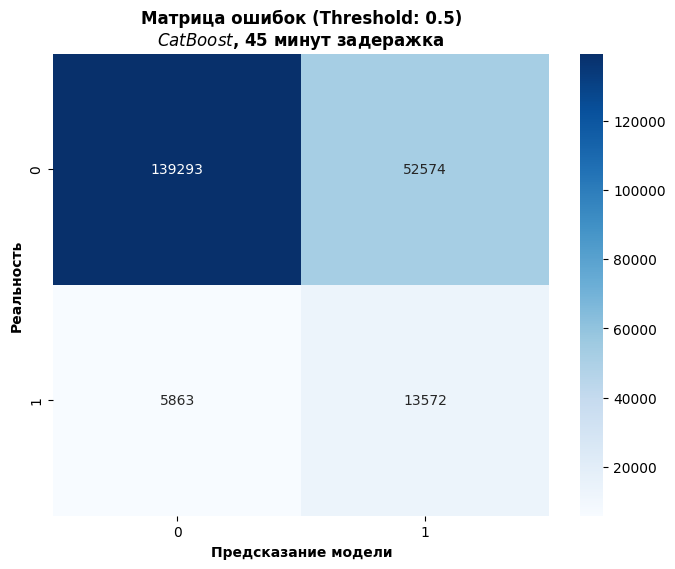

In [20]:
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Получаем вероятности (вместо жестких классов 0/1)
# Это нужно, чтобы мы могли управлять порогом чувствительности
y_probs = model_pipeline.predict_proba(X_test)[:, 1]

# 2. Устанавливаем порог. 
# Так как мы использовали scale_pos_weight, модель уже смещена.
# Начнем со стандартного 0.5. Если Recall будет ниже 0.80, его можно будет уменьшить.
threshold = 0.5
y_pred = (y_probs >= threshold).astype(int)

# 3. Считаем метрики
report45 = classification_report(y_test, y_pred)
auc_val45 = roc_auc_score(y_test, y_probs)

# Формируем итоговый текст
results_text45 = f"""
ОТЧЕТ ПО МОДЕЛИ ПРОГНОЗИРОВАНИЯ ЗАДЕРЖЕК (Задержка > 45 мин)
--------------------------------------------------
ВРЕМЯ ОБУЧЕНИЯ: {minutes} мин. {seconds} сек.
ROC-AUC SCORE: {auc_val45:.4f}
--------------------------------------------------
МЕТРИКИ КЛАССИФИКАЦИИ:
{report45}
"""

# Печатаем в консоль
print(results_text45)

# Сохраняем в файл .txt
with open("../notebooks/model_results_45.txt", "w", encoding="utf-8") as f:
    f.write(results_text45)

print("✅ Отчет сохранен в файл '../notebooks/model_results_45.txt'")

# 4. Визуализация матрицы ошибок (Confusion Matrix)
# Это наглядно покажет, сколько задержек мы поймали, а сколько - пропустили
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title(f'Матрица ошибок (Threshold: {threshold})\n$CatBoost$, 45 минут задеражка', weight='bold')
plt.ylabel('Реальность', weight='bold')
plt.xlabel('Предсказание модели', weight='bold')
plt.savefig('../notebooks/Матрица ошибок 45м.jpg', dpi=300)

plt.show()
plt.close()

In [ ]:
# Попытка разобраться с важностью признаков - этот анализ покажет, насколько правильным было выбор Feature Engineering
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Извлекаем важность признаков из модели внутри пайплайна
# Так как у нас Pipeline, мы обращаемся к шагу 'clf'
feature_importance = model_pipeline.named_steps['clf'].get_feature_importance()
feature_names = model_pipeline.named_steps['feature_eng'].transform(X_train.head(1)).columns

# 2. Создаем DataFrame для удобства визуализации
fi_df = pd.DataFrame({
    'feature': feature_names,
    'importance': feature_importance
}).sort_values(by='importance', ascending=False)

# 3. Визуализация
plt.figure(figsize=(14, 8))
sns.barplot(x='importance', y='feature', data=fi_df, palette='viridis')
plt.title('Важность признаков в модели CatBoost (Feature Importance)', weight='bold')
plt.xlabel('Вклад в предсказание (баллы)', weight='bold')
plt.ylabel('Признак', weight='bold')
plt.grid(True, axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('notebooks/CatBoost Feature Importance.jpg', dpi=300)

plt.show()
plt.close()

print('*Выведем Важность признаков (Feature Importance)\n\n', fi_df)



In [ ]:
# в поиске "идеального" Recall мы пожертвуем Precision и попытаемся узнать нужный нам порог.

import numpy as np
from sklearn.metrics import recall_score, precision_score

# Попробуем разные пороги
thresholds = [0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5]

# 1. Создаем "шапку" таблицы в строковой переменной
report_recall085 = f"{'Threshold':<12} | {'Recall':<10} | {'Precision':<10}\n"
report_recall085 += "-" * 38 + "\n"

# 2. Заполняем таблицу данными в цикле
for t in thresholds:
    y_pred_t = (y_probs >= t).astype(int)
    r = recall_score(y_test, y_pred_t)
    p = precision_score(y_test, y_pred_t)
    
    # Добавляем строку в общую переменную
    row = f"{t:<12} | {r:<10.4f} | {p:<10.4f}\n"
    report_recall085 += row

# 3. Выводим результат в консоль (чтобы видеть процесс)
print(report_recall085)

# 4. Формируем итоговый текст для файла
results_text_recall085 = f"""
ОТЧЕТ ПО УЛУЧШЕНИЮ RECALL ~ 85% (Задержки)
--------------------------------------------------
Данные получены путем перебора порогов классификации.
Целевой Recall (0.8435) достигается при пороге 0.35.
--------------------------------------------------
Таблица метрик:
{report_recall085}
"""

# 5. Сохраняем в файл .txt
with open("notebooks/recall085_results.txt", "w", encoding="utf-8") as f:
    f.write(results_text_recall085)
print("✅ Отчет успешно сохранен в файл 'recall085_results.txt'")

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

# Устанавливаем новый выбранный порог
final_threshold = 0.35
y_final_pred = (y_probs >= final_threshold).astype(int)

# Строим красивую матрицу
plt.figure(figsize=(10, 8))
cm_final = confusion_matrix(y_test, y_final_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_final, display_labels=['Вовремя', 'Задержка'])
disp.plot(cmap='Greens', values_format='d')
plt.title(f'Финальная матрица ошибок (Threshold: {final_threshold})', weight='bold')
plt.savefig('notebooks/new_conf_matrix_035.jpg', dpi=300)

plt.show()
plt.close()

print(f"Поймано задержек: {cm_final[1,1]} из {cm_final[1,0] + cm_final[1,1]}")

In [ ]:
# Так я недоволен метриками (Recall отличный, но Precision плох), попробуем проверить другой путь
# Посмотрим распределение задержек по разным порогам
delay_counts = pd.Series({
    "15+ мин (текущий)": (df['ARRIVAL_DELAY'] >= 15).sum(),
    "30+ мин":           (df['ARRIVAL_DELAY'] >= 30).sum(),
    "45+ мин":           (df['ARRIVAL_DELAY'] >= 45).sum(),
    "60+ мин":           (df['ARRIVAL_DELAY'] >= 60).sum()
})

delay_percents = (delay_counts / len(df)) * 100

print("Количество и доля задержек в данных:")
for label in delay_counts.index:
    print(f"{label:<18}: {delay_counts[label]:>8} рейс. ({delay_percents[label]:.2f}%)")